# Instances and dispatching schedules

Precedence graphs of instances and Gantt charts of dispatched schedules.
Model: `math/01_basic-fjsp.md`; rules: `math/11_dispatching-rules.md`.

Every schedule combines a **sequencing rule** (SPT, FIFO, MWKR, LRP) with either an **assignment rule**
(least load, ECT), which fixes the machine when an operation becomes ready, or **joint** mode, where the
sequencing rule ranks (operation, machine) pairs and so also chooses the machine.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt

import simulation
from simulation.check.feasibility import check_schedule
from simulation.io.brandimarte_loader import load_fjs
from simulation.io.json_loader import read_model
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.planners.dispatching import ASSIGNMENT_RULES, SEQUENCING_RULES, dispatch
from simulation.viz import plot_gantt, plot_orders

DATA = Path(simulation.__file__).parents[2] / "data"
ASSIGNMENTS = {**ASSIGNMENT_RULES, "joint": None}  # None: no assignment rule
COMBOS = [(s, a) for s in SEQUENCING_RULES for a in ASSIGNMENTS]


def makespan(schedule):
    return max(a.end for a in schedule)


def run(ci, s, a):
    return dispatch(ci, SEQUENCING_RULES[s], ASSIGNMENTS[a])


def gantts(ci, combos, name):
    fig, axes = plt.subplots(len(combos), 1, figsize=(12, (0.45 * ci.n_machines + 1.1) * len(combos)), squeeze=False)
    for ax, (s, a) in zip(axes[:, 0], combos):
        schedule = run(ci, s, a)
        title = f"{name} · {s.upper()} + {a} · makespan {makespan(schedule)} · {len(check_schedule(ci, schedule))} violations"
        plot_gantt(ci, schedule, ax=ax, title=title)
    fig.tight_layout()

## Toy instance with a branching order

Order B splits after b1 and reconverges at b4. Each box shows the operation ID and its eligible machines with processing times.

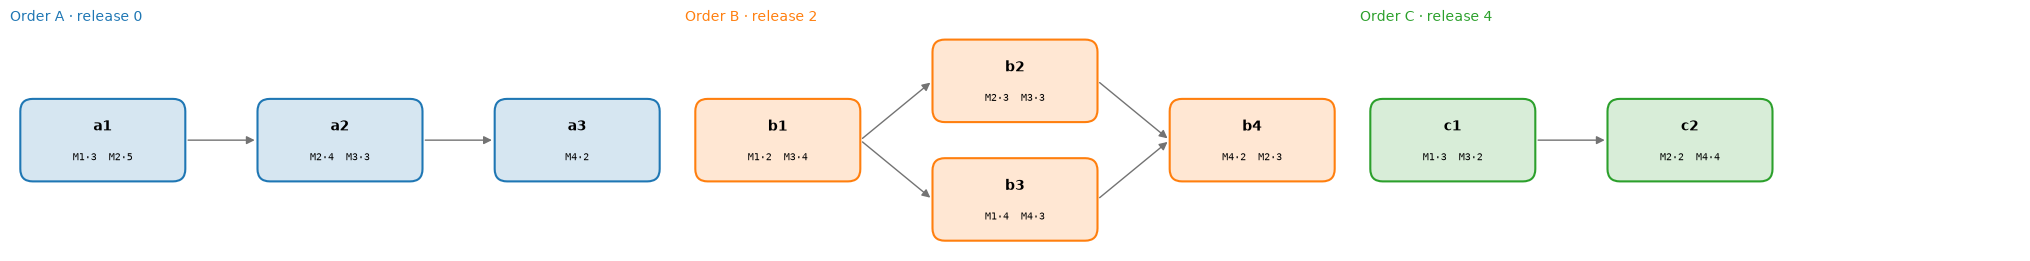

In [2]:
toy = compile_instance(read_model(DATA / "instances" / "toy-dag-3x4.json", Instance))
plot_orders(toy);

## SPT on the toy instance: least load vs. ECT vs. joint

Same sequencing rule, three ways of choosing the machine (hand computations in `math/11`, section 5).

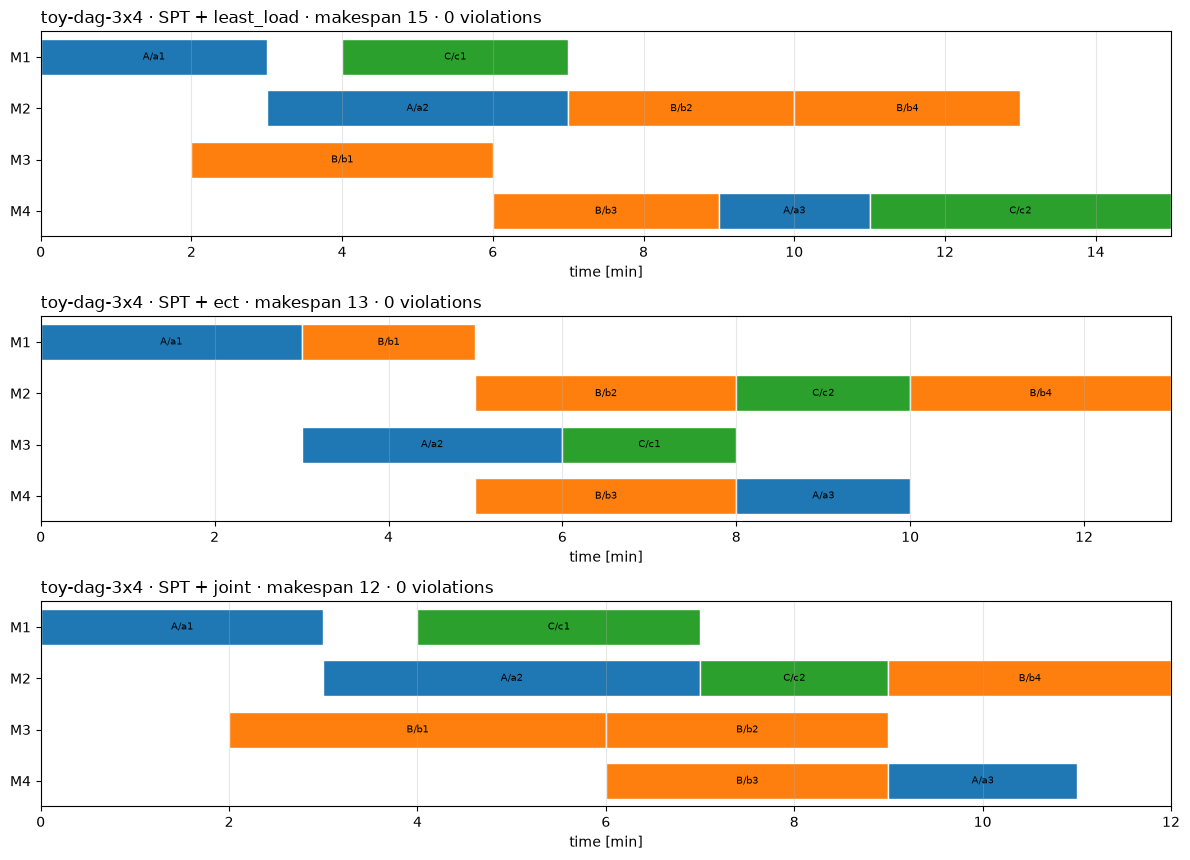

In [3]:
gantts(toy, [("spt", a) for a in ASSIGNMENTS], "toy-dag-3x4")

In [4]:
print(f"{'':6}" + "".join(f"{a:>12}" for a in ASSIGNMENTS))
for s in SEQUENCING_RULES:
    print(f"{s:6}" + "".join(f"{makespan(run(toy, s, a)):>12}" for a in ASSIGNMENTS))

        least_load         ect       joint
spt             15          13          12
fifo            15          13          12
mwkr            15          13          12
lrp             15          13          12


## Brandimarte mk01

The first three orders (chains), then MWKR with ECT and in joint mode.

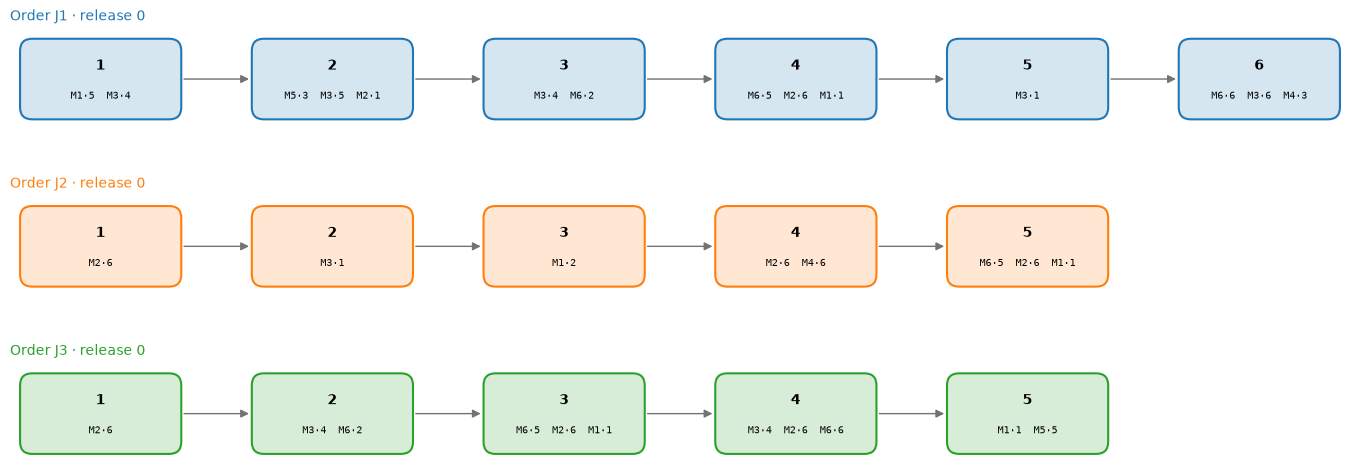

In [5]:
mk01 = compile_instance(load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs"))
plot_orders(mk01, mk01.order_ids[:3], ncols=1);

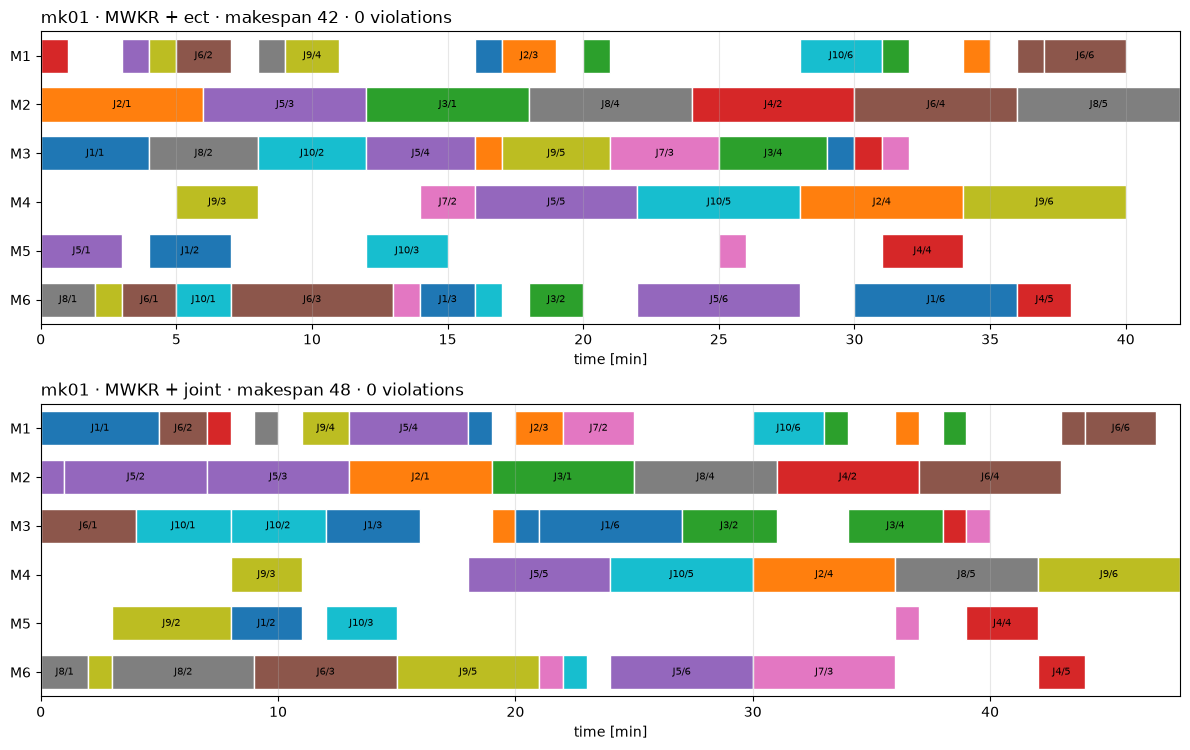

In [6]:
gantts(mk01, [("mwkr", "ect"), ("mwkr", "joint")], "mk01")

## Makespan of every rule combination on all Brandimarte instances

Columns: sequencing rule / assignment (LL = least load, ECT, J = joint). Own computation; no comparison with
best-known values from the literature yet. On chains (all Brandimarte instances) MWKR and LRP coincide by definition.

In [7]:
short = {"least_load": "LL", "ect": "ECT", "joint": "J"}
paths = sorted((DATA / "benchmarks" / "brandimarte").glob("*.fjs"), key=lambda p: int(p.stem.removeprefix("BrandimarteMk")))
print(f"{'':6}" + "".join(f"{s + '/' + short[a]:>10}" for s, a in COMBOS))
for path in paths:
    ci = compile_instance(load_fjs(path))
    print(f"{path.stem.removeprefix('Brandimarte'):6}" + "".join(f"{makespan(run(ci, s, a)):>10}" for s, a in COMBOS))

          spt/LL   spt/ECT     spt/J   fifo/LL  fifo/ECT    fifo/J   mwkr/LL  mwkr/ECT    mwkr/J    lrp/LL   lrp/ECT     lrp/J
Mk1           52        42        55        47        42        47        49        42        48        49        42        48
Mk2           46        32        55        39        31        31        38        30        33        38        30        33
Mk3          230       221       268       209       204       217       217       204       204       217       204       204
Mk4           90        73        78        82        75        76        80        70        75        80        70        75
Mk5          201       197       224       188       188       189       183       184       186       183       184       186
Mk6          103        79        82        95        74        79        97        73        88        97        73        88
Mk7          229       176       227       204       158       176       207       150       190       207     

Mk9          397       379       431       354       345       369       328       311       327       328       311       327
Mk10         290       247       375       293       237       279       276       227       266       276       227       266
